# Experiment — dataset 01 *with STDP + WTA*: learning on the three-channel network

### The Johnston's organ (JO) topology, with modulators kept as a channel of their own, now **learns**

**Trabajo de Integración Curricular** — *Bio-Inspired Neuromorphic Coding for Efficient Edge AI with Spiking Neural Networks* — UTPL 2026

---

## What we do here, and why

Dataset 01 (raw connectome weights) simulated the JO network with static weights, keeping the three synapse types of the connectome in **separate channels**.

| Type | Neurotransmitter | Channel | τ |
|---|---|---|---|
| Excitatory | ACH | `I_exc` | 5 ms (fast) |
| Inhibitory | GABA/GLUT | `I_inh` | 10 ms |
| **Modulatory** | SER/DA/OCT | `I_mod` | **50 ms** (slow) |

That experiment showed that the modulators, barely 2 % of the synapses, carry a large functional effect (12–27 % in firing rate and propagation), and that normalizing by the **mean** produces the most balanced regime. Two questions were left open.

1. **Does the advantage of the mean survive once the network learns?** Dataset 02 found the mean to be the most stable scheme under STDP, but the modulators there had been collapsed into excitatory synapses. Here we keep them as a slow channel of their own, so the check has to be made directly.
2. **The mean has a weak spot.** Its JO→AMMC propagation ratio sits at 0.162, under the 0.3 threshold. Can we raise it by touching `alpha_mod`, the gain of the modulatory channel, without breaking the stability of learning?

## What this notebook adds on top of dataset 01

- **STDP** (spike-timing-dependent plasticity) on the **excitatory** synapses. Modulatory and inhibitory synapses stay static, since their job is to set gain and balance rather than to learn.
- **WTA** (winner-take-all), lateral competition that pushes neurons to specialize.
- **Learning metrics**, `|Δw|`, final variance, drift and selectivity, on top of the dynamics metrics of dataset 01 (firing rate, coverage, efficiency, propagation ratio and the rest).
- A **sweep of `alpha_mod`**, for the mean only, aimed at repairing the propagation ratio.

We treat **mean** and **median** as the main candidates. **shiu** and **log** come along only to check whether the trend observed in dataset 02 still holds.

> **Sensory input:** a single Poisson group at 100 Hz onto the JO neurons, the simplified regime shared by all the early experiments. Real auditory coding and the classification task arrive in later phases.


## 0. Environment setup

Brian2 as the simulation core, plus the usual scientific stack. The seed is fixed for reproducibility. Data are the same ones the EDA produced in phases 2 and 3, read from `01-data-understanding/outputs/`.


In [1]:
import warnings
warnings.filterwarnings('ignore')

from brian2 import *      # NeuronGroup, Synapses, units (mV, ms, nA...), run, seed
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Filtered subgraph written by the EDA notebook of phase 2.
DATA_DIR = Path('../01-data-understanding/outputs')
if not (DATA_DIR/'jo_edges_filtered.csv').exists():
    DATA_DIR = Path('.')                     # Colab: files uploaded next to the notebook
OUT_DIR  = Path('outputs/04-dataset01-stdp'); OUT_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
np.random.seed(SEED)

plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
                     'axes.titleweight': 'bold', 'font.size': 10})

print('Environment ready.  brian2', __import__('brian2').__version__,
      '| numpy', np.__version__, '| data in', DATA_DIR)

Environment ready.  brian2 2.10.1 | numpy 2.4.6 | data in ../01-data-understanding/outputs


## 1. Loading the JO subgraph and sorting synapses into three types

Same as in dataset 01. We load the biological topology and we do **not** collapse the modulators. Every synapse is labelled excitatory (+1), inhibitory (−1) or modulatory (0), and each type feeds its own channel in the LIF model.


In [2]:
nodes = pd.read_csv(DATA_DIR/'jo_nodes_filtered.csv')
edges = pd.read_csv(DATA_DIR/'jo_edges_filtered.csv')
if nodes['is_jo'].dtype != bool:
    nodes['is_jo'] = nodes['is_jo'].astype(str).str.lower().map({'true': True, 'false': False})

# Integer indices 0..N-1, which is what Brian2 expects
node_ids  = sorted(set(edges['pre']).union(edges['post']))
id_to_idx = {n: i for i, n in enumerate(node_ids)}
N = len(node_ids)
pre_idx  = edges['pre'].map(id_to_idx).to_numpy(np.int32)
post_idx = edges['post'].map(id_to_idx).to_numpy(np.int32)
w_raw    = edges['weight'].to_numpy(np.float64)          # raw syn_count (long tail)

# THREE types: +1 exc, -1 inh, 0 mod. Keys are the labels stored in the CSV.
TYPE_MAP  = {'Excitatory': 1, 'Inhibitory': -1, 'Modulatory': 0}
syn_types = edges['polarity'].map(TYPE_MAP).fillna(1).to_numpy(np.int32)
exc = syn_types == 1
inh = syn_types == -1
mod = syn_types == 0

# Sensory JO neurons (Poisson input) vs AMMC partners (second order)
jo_root = set(nodes.loc[nodes['is_jo'], 'root_id'])
jo_indices = np.array([id_to_idx[n] for n in node_ids if n in jo_root], dtype=np.int32)
n_jo = len(jo_indices); n_partners = N - n_jo

print(f'Nodes: {N}  ·  JO (input): {n_jo}  ·  AMMC partners: {n_partners}')
print(f'Synapses: {len(w_raw):,}  ->  exc {int(exc.sum()):,} ({100*exc.mean():.1f}%) | '
      f'inh {int(inh.sum()):,} ({100*inh.mean():.1f}%) | mod {int(mod.sum()):,} ({100*mod.mean():.1f}%)')
print(f'Raw weight: mean={w_raw.mean():.2f}  median={np.median(w_raw):.1f}  max={w_raw.max():.0f}  '
      f'(long tail, mean >> median)')

Nodes: 1239  ·  JO (input): 269  ·  AMMC partners: 970
Synapses: 20,059  ->  exc 8,940 (44.6%) | inh 10,674 (53.2%) | mod 445 (2.2%)
Raw weight: mean=16.85  median=10.0  max=347  (long tail, mean >> median)


## 2. The four normalization schemes

Raw `syn_count` has a long tail (mean far above median), so it has to be normalized before being injected. Each scheme decides which scale to privilege. Normalization is applied the same way to all three synapse types, and each channel then receives its own gain `alpha` (section 3).

| Scheme | Formula | What it does |
|---|---|---|
| `mean` | `w = c / mean(c)` | typical weight ≈ 1; linear, keeps the tail. **Main candidate.** |
| `median` | `w = c / median(c)` | robust center, raises gain (median < mean). **Main candidate.** |
| `shiu` | `w = c` (absolute weights) | replicates Shiu et al.; calibration happens in `alpha`. Kept only to see the trend. |
| `log` | `w = log(1+c) / mean(log(1+c))` | non-linear, compresses the tail. Kept only to see the trend. |


In [3]:
def normalize(c, scheme):
    if scheme == 'mean':   return c / c.mean()
    if scheme == 'median': return c / np.median(c)
    if scheme == 'shiu':   return c.copy()                 # absolute weights; calibrated in alpha
    if scheme == 'log':    lc = np.log1p(c); return lc / lc.mean()
    raise ValueError(scheme)

SCHEMES = ['mean', 'median', 'shiu', 'log']
COLORS  = {'mean': '#2E86AB', 'median': '#E1A730', 'shiu': '#C73E1D', 'log': '#5B8C5A'}

# alpha gains per channel and scheme (nA). shiu uses a reduced alpha because its weights are absolute.
#   (alpha_exc, alpha_inh, alpha_mod)  -- values from dataset 01
ALPHAS = {
    'mean':   (1.5, 0.75, 0.5),
    'median': (1.5, 0.75, 0.5),
    'log':    (1.5, 0.75, 0.5),
    'shiu':   (0.15, 0.075, 0.05),
}

w_by_scheme = {s: normalize(w_raw, s) for s in SCHEMES}

print(f"{'scheme':<9}{'mean_w':>9}{'median_w':>11}{'max_w':>9}   alpha(exc,inh,mod) nA")
for s in SCHEMES:
    ws = w_by_scheme[s][exc]
    print(f'{s:<9}{ws.mean():>9.3f}{np.median(ws):>11.3f}{ws.max():>9.2f}   {ALPHAS[s]}')

scheme      mean_w   median_w    max_w   alpha(exc,inh,mod) nA
mean         0.960      0.593    20.00   (1.5, 0.75, 0.5)
median       1.618      1.000    33.70   (1.5, 0.75, 0.5)
shiu        16.179     10.000   337.00   (0.15, 0.075, 0.05)
log          0.991      0.933     2.27   (1.5, 0.75, 0.5)


## 3. Three-channel LIF model, plus STDP and WTA

### 3.1. Equations (identical to dataset 01)

$$\tau_m \frac{dv}{dt} = -(v - V_{rest}) + R_m\,(I_{exc} + I_{inh} + I_{mod}), \qquad \frac{dI_k}{dt} = -\frac{I_k}{\tau_{syn,k}}$$

with $\tau_{exc}=5$ ms, $\tau_{inh}=10$ ms, $\tau_{mod}=50$ ms. What is new here is that the **excitatory** synapses carry STDP, and that a WTA population supplies lateral inhibition.

### 3.2. What WTA is and why it is used

WTA is a mechanism of lateral competition. A small inhibitory population receives excitation from the whole network and sends inhibition back to all of it. In practice the neuron that fires first, or hardest, silences the others. Without WTA, under STDP every neuron would tend to strengthen the same connections and respond to the same pattern, which is a redundant representation. WTA breaks that tie, so different neurons specialize in different patterns. It is the ingredient that turns plasticity into useful unsupervised learning (Diehl & Cook, 2015). We measure it through **selectivity** (sparseness). The higher the selectivity, the stronger the specialization.

### 3.3. What `alpha_mod` is and why we vary it

`alpha_mod` is the gain of the modulatory channel, how much current each modulatory spike injects into `I_mod`. Because `I_mod` decays slowly (τ=50 ms), it acts as a slow depolarization floor that keeps neurons near threshold over long windows. Raising `alpha_mod` lifts that floor, so the AMMC partner neurons downstream, weakly connected as they are, cross threshold without needing such exact temporal coincidence. The JO→AMMC propagation ratio should rise as a result, and that is precisely where the mean is weak.

There is a risk. Push it too far and the network over-excites, with the global rate leaving the 15–30 Hz range. We are looking for the `alpha_mod` that improves propagation without wrecking either the regime or the stability of learning. We sweep it for the mean only (section 6).

### 3.4. STDP (Song et al., 2000; Diehl & Cook, 2015)

`event-driven` traces, asymmetry $A_- > A_+$ to stabilize, and a bound `wmax = 4·initial mean weight` that is relative to each scheme so that plasticity stays comparable across very different magnitudes.


In [4]:
def simulate(scheme, with_stdp, alpha_mod_override=None, seed_val=SEED, T=1000):
    """Three-channel JO network (exc/inh/mod). with_stdp turns on STDP+WTA over the excitatory synapses.
    alpha_mod_override forces the modulatory gain (used by the sweep). Returns the metrics."""
    start_scope(); seed(seed_val); defaultclock.dt = 0.1*ms
    T_sim = T*ms

    w_norm = w_by_scheme[scheme]
    a_exc, a_inh, a_mod = ALPHAS[scheme]
    if alpha_mod_override is not None:
        a_mod = alpha_mod_override
    alpha_exc, alpha_inh, alpha_mod = a_exc*nA, a_inh*nA, a_mod*nA

    # LIF parameters (three channels)
    tau_m=10*ms; V_rest=-65*mV; V_thresh=-52*mV; V_reset=-65*mV
    tau_ref=2*ms; R_m=10*Mohm; tau_exc=5*ms; tau_inh=10*ms; tau_mod=50*ms
    w_input=3.0*nA
    NS = {'V_rest':V_rest,'V_thresh':V_thresh,'V_reset':V_reset,'tau_m':tau_m,'R_m':R_m,
          'tau_exc':tau_exc,'tau_inh':tau_inh,'tau_mod':tau_mod}

    eqs = '''
    dv/dt     = (-(v - V_rest) + R_m*(I_exc + I_inh + I_mod))/tau_m : volt (unless refractory)
    dI_exc/dt = -I_exc/tau_exc : amp
    dI_inh/dt = -I_inh/tau_inh : amp
    dI_mod/dt = -I_mod/tau_mod : amp
    '''
    G = NeuronGroup(N, eqs, threshold='v>V_thresh', reset='v=V_reset',
                    refractory=tau_ref, method='euler', namespace=NS)
    G.v = V_rest + np.random.uniform(0,1,N)*(V_thresh-V_rest)

    # Poisson input at 100 Hz onto the JO neurons -> excitatory channel
    G_in = PoissonGroup(n_jo, rates=100*Hz)
    S_in = Synapses(G_in, G, on_pre='I_exc_post += w_input', namespace={'w_input':w_input})
    S_in.connect(i=np.arange(n_jo), j=jo_indices)
    objs = [G, G_in, S_in]

    w_exc = w_norm[exc]

    # --- Excitatory synapses: STDP (or static) on the I_exc channel ---
    if not with_stdp:
        S_exc = Synapses(G, G, model='w:1', on_pre='I_exc_post += alpha_exc*w',
                         namespace={'alpha_exc':alpha_exc})
        S_exc.connect(i=pre_idx[exc], j=post_idx[exc]); S_exc.w = w_exc
        w_init = None
    else:
        wmax = 4.0*float(np.mean(w_exc))
        taupre=taupost=20*ms; Aplus=0.05; Aminus=0.0525
        model='''w:1
        dapre/dt=-apre/taupre:1 (event-driven)
        dapost/dt=-apost/taupost:1 (event-driven)'''
        on_pre='''I_exc_post += alpha_exc*w
        apre += Aplus
        w = clip(w+apost,0,wmax)'''
        on_post='''apost += -Aminus
        w = clip(w+apre,0,wmax)'''
        S_exc = Synapses(G, G, model=model, on_pre=on_pre, on_post=on_post,
                         namespace={'alpha_exc':alpha_exc,'taupre':taupre,'taupost':taupost,
                                    'Aplus':Aplus,'Aminus':Aminus,'wmax':wmax})
        S_exc.connect(i=pre_idx[exc], j=post_idx[exc])
        S_exc.w = np.clip(w_exc, 0, wmax)
        w_init = np.array(S_exc.w[:])
    objs.append(S_exc)

    # --- Inhibitory and modulatory: ALWAYS static (they set balance and gain) ---
    S_inh = Synapses(G, G, model='w:1', on_pre='I_inh_post -= alpha_inh*w',
                     namespace={'alpha_inh':alpha_inh})
    S_inh.connect(i=pre_idx[inh], j=post_idx[inh]); S_inh.w = w_norm[inh]
    objs.append(S_inh)

    S_mod = Synapses(G, G, model='w:1', on_pre='I_mod_post += alpha_mod*w',
                     namespace={'alpha_mod':alpha_mod})
    if mod.sum() > 0:
        S_mod.connect(i=pre_idx[mod], j=post_idx[mod]); S_mod.w = w_norm[mod]
    objs.append(S_mod)

    spk = SpikeMonitor(G); rate = PopulationRateMonitor(G)
    objs += [spk, rate]

    wmon = None
    if with_stdp:
        # WTA: inhibitory population providing global lateral inhibition
        N_wta = min(N, 50)
        G_inh = NeuronGroup(N_wta, eqs, threshold='v>V_thresh', reset='v=V_reset',
                            refractory=tau_ref, method='euler', namespace=NS)
        G_inh.v = V_rest; G_inh.I_exc = 0*nA; G_inh.I_inh = 0*nA; G_inh.I_mod = 0*nA
        S_e2i = Synapses(G, G_inh, on_pre='I_exc_post += wta_exc', namespace={'wta_exc':1.0*nA})
        S_e2i.connect(j='i % N_wta')
        S_i2e = Synapses(G_inh, G, on_pre='I_inh_post -= wta_inh', namespace={'wta_inh':0.5*nA})
        S_i2e.connect()
        wmon = StateMonitor(S_exc, 'w', record=range(min(300, len(w_exc))))
        objs += [G_inh, S_e2i, S_i2e, wmon]

    net = Network(*objs); net.run(T_sim, report=None)

    # ===== Metrics =====
    Tsec = float(T_sim/second)
    t = np.array(spk.t/ms); i = np.array(spk.i)
    counts = np.array(spk.count); r = counts/Tsec
    n_active = int((counts > 0).sum())

    # Dynamics
    mean_rate = spk.num_spikes/N/Tsec
    coverage  = 100*n_active/N
    efficiency = spk.num_spikes/(len(pre_idx)*Tsec)
    # ISI CV (neurons with >=3 spikes)
    cvs = []
    for n in np.unique(i):
        ts = np.sort(t[i == n])
        if len(ts) >= 3:
            isi = np.diff(ts)
            if isi.mean() > 0: cvs.append(isi.std()/isi.mean())
    cv_isi = float(np.mean(cvs)) if cvs else float('nan')
    rs = np.array(rate.smooth_rate(window='gaussian', width=10*ms)/Hz)
    synchrony = float(rs.std()/rs.mean()) if rs.mean() > 0 else float('nan')
    # Propagation JO -> partners
    is_jo_spk = np.isin(i, jo_indices)
    jo_rate      = int(is_jo_spk.sum())/n_jo/Tsec
    partner_rate = int((~is_jo_spk).sum())/n_partners/Tsec if n_partners > 0 else float('nan')
    prop_ratio   = partner_rate/jo_rate if jo_rate > 0 else float('nan')
    # Selectivity (Treves-Rolls sparseness): 0=uniform, 1=selective
    sparseness = (1 - (r.mean()**2)/np.mean(r**2))/(1 - 1.0/N) if r.sum() > 0 else 0.0

    out = {'scheme':scheme, 'alpha_mod':a_mod, 'with_stdp':with_stdp,
           'total_spikes':int(spk.num_spikes), 'mean_rate_hz':float(mean_rate),
           'coverage_pct':float(coverage), 'efficiency':float(efficiency),
           'cv_isi':cv_isi, 'synchrony':synchrony,
           'jo_rate':float(jo_rate), 'partner_rate':float(partner_rate),
           'propagation_ratio':float(prop_ratio), 'selectivity':float(sparseness),
           't':t, 'i':i}
    if with_stdp:
        w_final = np.array(S_exc.w[:]); dw = w_final - w_init
        traj = np.array(wmon.w).mean(axis=0)
        k = max(1, int(0.2*len(traj)))
        out.update({'w_init':w_init, 'w_final':w_final,
                    'dw_abs_mean':float(np.abs(dw).mean()),
                    'w_var_final':float(w_final.var()),
                    'drift_final':float(np.std(traj[-k:])),
                    'traj':traj, 'traj_t':np.array(wmon.t/ms)})
    return out

## 4. Part A — the four schemes compared, baseline against STDP+WTA

For each scheme we run **two conditions** with the same seed and the default `alpha_mod`.

1. **Baseline**, no plasticity, which gives the starting dynamic regime.
2. **STDP + WTA**, learning.

That covers two questions at once. Which scheme learns most stably with the three channels, and how much the dynamics metrics move when plasticity is switched on, comparing baseline against STDP within the same network.


In [5]:
results = {}
for s in SCHEMES:
    print(f'== Scheme: {s} ==')
    base = simulate(s, with_stdp=False)
    stdp = simulate(s, with_stdp=True)
    results[s] = {'base': base, 'stdp': stdp}
    print(f'   base -> rate {base["mean_rate_hz"]:.2f} Hz | active {base["coverage_pct"]:.1f}% '
          f'| prop_ratio {base["propagation_ratio"]:.3f} | select {base["selectivity"]:.3f}')
    print(f'   stdp -> rate {stdp["mean_rate_hz"]:.2f} Hz | prop_ratio {stdp["propagation_ratio"]:.3f} '
          f'| |dw| {stdp["dw_abs_mean"]:.4f} | var {stdp["w_var_final"]:.4f} | drift {stdp["drift_final"]:.4f}')
print('\nPart A done: 4 schemes x 2 conditions.')

== Scheme: mean ==


WARNING    Removing unsupported flag '-march=native' from compiler flags. [brian2.codegen.cpp_prefs]


   base -> rate 16.09 Hz | active 41.8% | prop_ratio 0.162 | select 0.769
   stdp -> rate 4.49 Hz | prop_ratio 0.032 | |dw| 0.0049 | var 0.6820 | drift 0.0002
== Scheme: median ==


   base -> rate 27.87 Hz | active 48.5% | prop_ratio 0.389 | select 0.818
   stdp -> rate 4.45 Hz | prop_ratio 0.112 | |dw| 0.0173 | var 1.9539 | drift 0.0002
== Scheme: shiu ==


   base -> rate 27.87 Hz | active 48.5% | prop_ratio 0.389 | select 0.818
   stdp -> rate 4.18 Hz | prop_ratio 0.114 | |dw| 0.0131 | var 192.3829 | drift 0.0001
== Scheme: log ==


   base -> rate 23.12 Hz | active 49.3% | prop_ratio 0.342 | select 0.777
   stdp -> rate 4.46 Hz | prop_ratio 0.041 | |dw| 0.0059 | var 0.0729 | drift 0.0006

Part A done: 4 schemes x 2 conditions.


## 5. Part A figures

### 5.1. Baseline dynamics per scheme

What we want is sparse but structured activity: 15–30 Hz, coverage above 40 %, propagation ratio above 0.3.


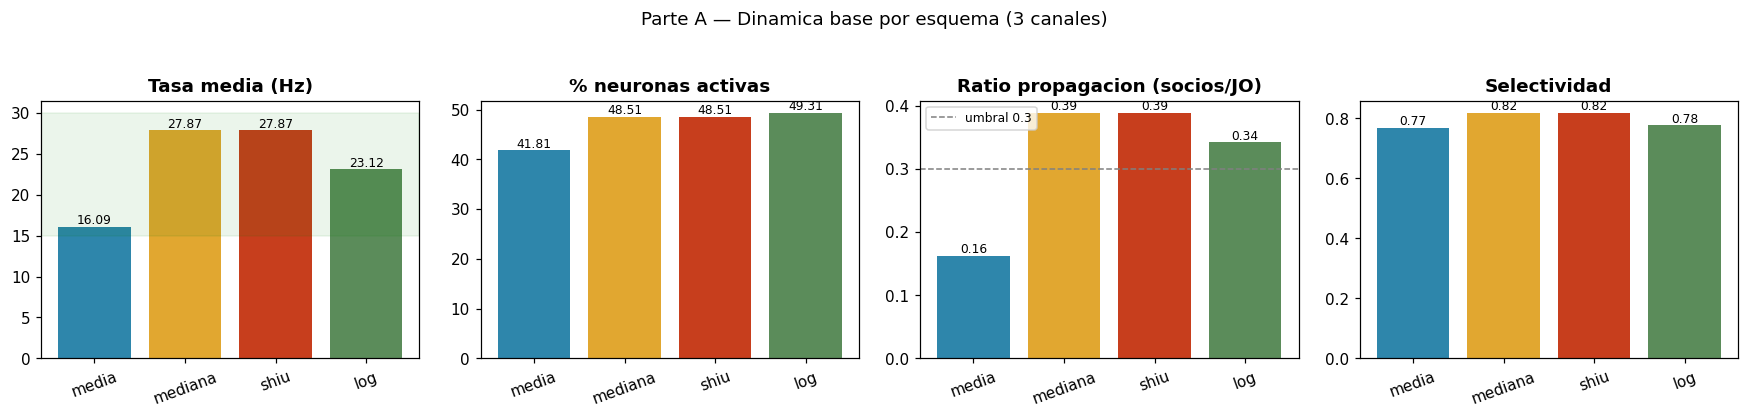

In [6]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))
met = [('mean_rate_hz','Mean rate (Hz)'), ('coverage_pct','% active neurons'),
       ('propagation_ratio','Propagation ratio (partners/JO)'), ('selectivity','Selectivity')]
for a,(k,tit) in zip(ax, met):
    vals = [results[s]['base'][k] for s in SCHEMES]
    bars = a.bar(SCHEMES, vals, color=[COLORS[s] for s in SCHEMES])
    a.set_title(tit); a.tick_params(axis='x', rotation=20)
    for i,v in enumerate(vals): a.text(i, v, f'{v:.2f}', ha='center', va='bottom', fontsize=8)
    if k=='propagation_ratio': a.axhline(0.3, color='gray', ls='--', lw=1, label='threshold 0.3'); a.legend(fontsize=8)
    if k=='mean_rate_hz': a.axhspan(15,30, color='green', alpha=0.08)
fig.suptitle('Part A — baseline dynamics per scheme (three channels)', y=1.04)
fig.tight_layout(); fig.savefig(OUT_DIR/'fig01_baseline_dynamics_four_schemes.png'); plt.show()

### 5.2. Do the metrics move when STDP+WTA is switched on?

Here the same network is compared before (baseline) and after (STDP+WTA). Bars that barely move would mean plasticity refines the regime without altering it. Large changes would mean STDP reorganizes the dynamics.


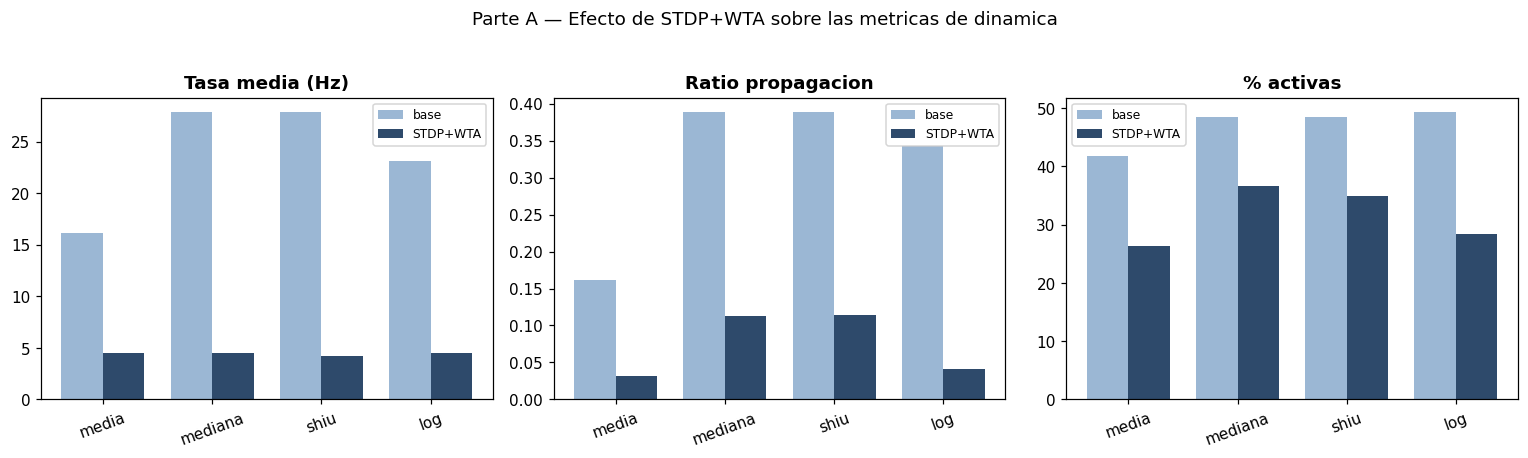

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
x = np.arange(len(SCHEMES)); wbar = 0.38
for a,(k,tit) in zip(ax, [('mean_rate_hz','Mean rate (Hz)'),
                          ('propagation_ratio','Propagation ratio'),
                          ('coverage_pct','% active')]):
    vb = [results[s]['base'][k] for s in SCHEMES]
    vs = [results[s]['stdp'][k] for s in SCHEMES]
    a.bar(x-wbar/2, vb, wbar, label='baseline', color='#9BB7D4')
    a.bar(x+wbar/2, vs, wbar, label='STDP+WTA', color='#2E4A6B')
    a.set_xticks(x); a.set_xticklabels(SCHEMES, rotation=20); a.set_title(tit); a.legend(fontsize=8)
fig.suptitle('Part A — effect of STDP+WTA on the dynamics metrics', y=1.03)
fig.tight_layout(); fig.savefig(OUT_DIR/'fig02_baseline_vs_stdp.png'); plt.show()

### 5.3. Stability of learning

`|Δw|` says how far the weights moved. **Final variance** and **drift** speak to stability, and lower is better since it means cleaner convergence. Drift is the `std` of the mean weight over the last 20 % of the simulation.


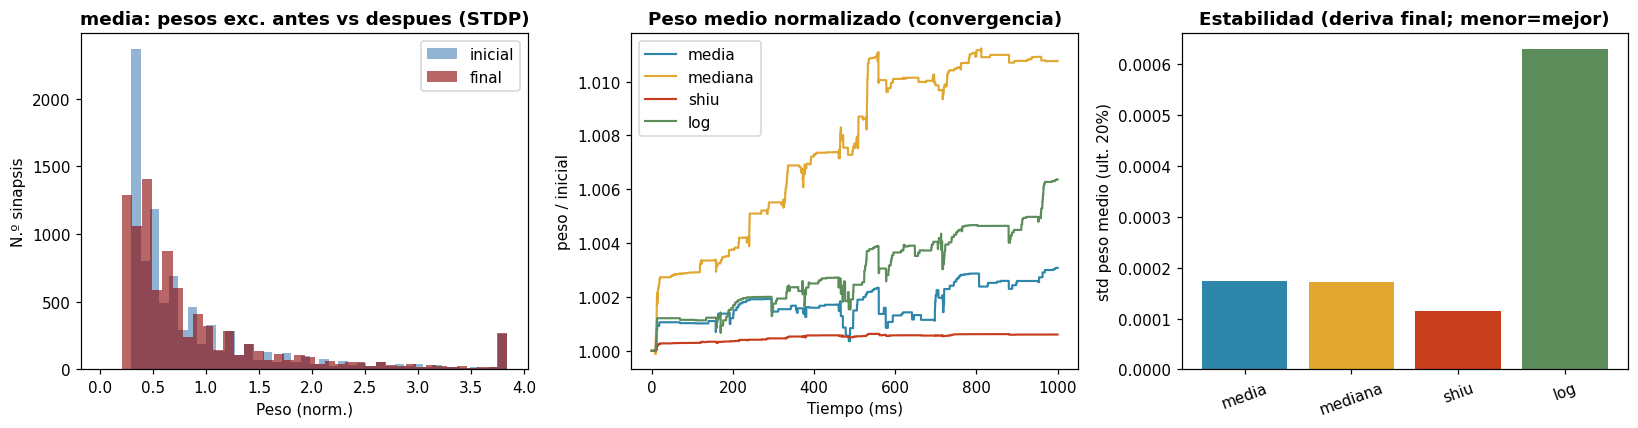

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
# (a) initial vs final for 'mean'
ref = results['mean']['stdp']
ax[0].hist(ref['w_init'], bins=40, alpha=0.6, label='initial', color='steelblue')
ax[0].hist(ref['w_final'], bins=40, alpha=0.6, label='final', color='darkred')
ax[0].set(title='mean: exc. weights before vs after (STDP)', xlabel='Weight (norm.)', ylabel='No. of synapses'); ax[0].legend()
# (b) trajectory of the mean weight (convergence)
for s in SCHEMES:
    st = results[s]['stdp']
    ax[1].plot(st['traj_t'], st['traj']/st['traj'][0], color=COLORS[s], lw=1.4, label=s)
ax[1].set(title='Normalized mean weight (convergence)', xlabel='Time (ms)', ylabel='weight / initial'); ax[1].legend()
# (c) final drift
drift = [results[s]['stdp']['drift_final'] for s in SCHEMES]
ax[2].bar(SCHEMES, drift, color=[COLORS[s] for s in SCHEMES])
ax[2].set(title='Stability (final drift; lower=better)', ylabel='std of mean weight (last 20%)'); ax[2].tick_params(axis='x', rotation=20)
fig.tight_layout(); fig.savefig(OUT_DIR/'fig03_weight_stability.png'); plt.show()

## 6. Part B — sweeping `alpha_mod` (mean only)

The weak spot of the mean is its propagation ratio, below 0.3. We raise the modulatory gain `alpha_mod` from `0.5`, the dataset 01 value, to `1.0` and `1.5`, leaving everything else untouched, and we look at three things. Whether the propagation ratio goes up, which is the goal. Whether the mean rate stays inside the physiological 15–30 Hz range, our check against over-excitation. And whether learning stability, measured as drift, survives.

Each `alpha_mod` runs twice, baseline for the dynamics and STDP for the stability.


In [9]:
ALPHA_MOD_VALS = [0.5, 1.0, 1.5]
sweep = {}
for am in ALPHA_MOD_VALS:
    b = simulate('mean', with_stdp=False, alpha_mod_override=am)
    s = simulate('mean', with_stdp=True,  alpha_mod_override=am)
    sweep[am] = {'base': b, 'stdp': s}
    print(f'alpha_mod={am:>3} -> rate {b["mean_rate_hz"]:.2f} Hz | partner_rate {b["partner_rate"]:.2f} '
          f'| prop_ratio {b["propagation_ratio"]:.3f} | coverage {b["coverage_pct"]:.1f}% '
          f'| drift {s["drift_final"]:.4f}')

WARNING    'v' is an internal variable of group 'neurongroup', but also exists in the run namespace with the value 0.7766567688740995. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


WARNING    'i' is an internal variable of group 'synapses_4', but also exists in the run namespace with the value 3. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


WARNING    'v' is an internal variable of group 'neurongroup_1', but also exists in the run namespace with the value 0.7766567688740995. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


WARNING    'v' is an internal variable of group 'neurongroup_2', but also exists in the run namespace with the value 0.7766567688740995. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


alpha_mod=0.5 -> rate 16.09 Hz | partner_rate 7.58 | prop_ratio 0.162 | coverage 41.8% | drift 0.0002


alpha_mod=1.0 -> rate 23.58 Hz | partner_rate 16.65 | prop_ratio 0.343 | coverage 45.9% | drift 0.0001


alpha_mod=1.5 -> rate 31.89 Hz | partner_rate 26.13 | prop_ratio 0.496 | coverage 45.0% | drift 0.0001


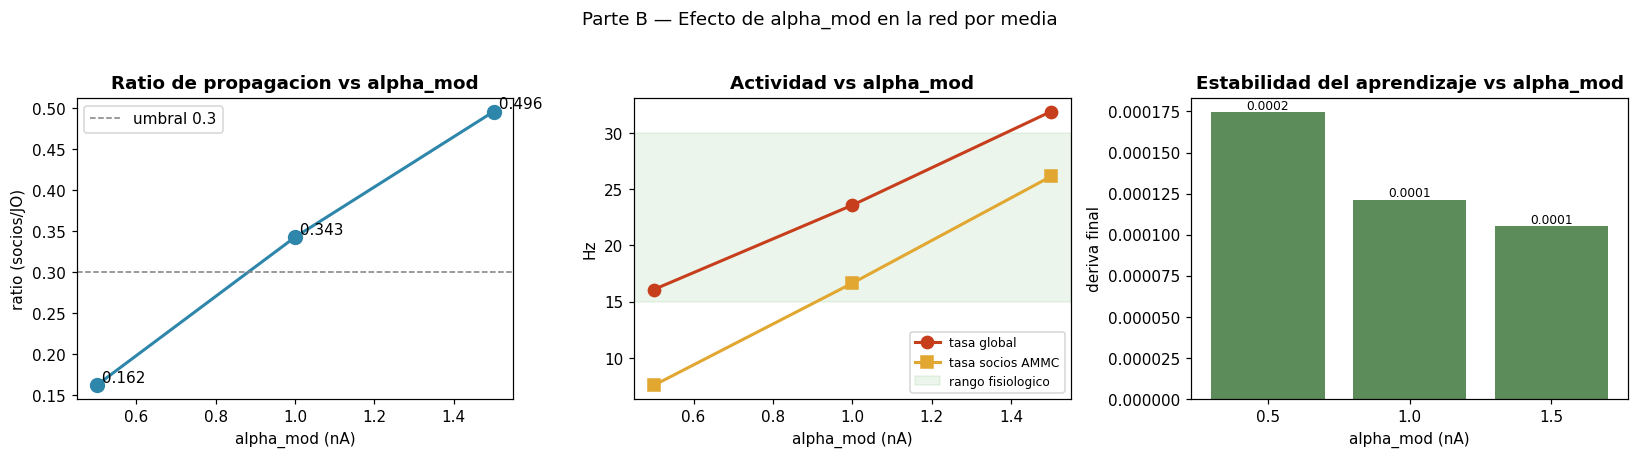

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ams = ALPHA_MOD_VALS
# (a) propagation ratio vs alpha_mod
rp = [sweep[a]['base']['propagation_ratio'] for a in ams]
ax[0].plot(ams, rp, 'o-', color='#2E86AB', lw=2, ms=9)
ax[0].axhline(0.3, color='gray', ls='--', lw=1, label='threshold 0.3')
for a,v in zip(ams, rp): ax[0].text(a, v, f' {v:.3f}', va='bottom')
ax[0].set(title='Propagation ratio vs alpha_mod', xlabel='alpha_mod (nA)', ylabel='ratio (partners/JO)'); ax[0].legend()
# (b) mean rate vs alpha_mod (over-excitation check)
tm = [sweep[a]['base']['mean_rate_hz'] for a in ams]
ts = [sweep[a]['base']['partner_rate'] for a in ams]
ax[1].plot(ams, tm, 'o-', label='global rate', color='#C73E1D', lw=2, ms=8)
ax[1].plot(ams, ts, 's-', label='AMMC partner rate', color='#E1A730', lw=2, ms=8)
ax[1].axhspan(15,30, color='green', alpha=0.08, label='physiological range')
ax[1].set(title='Activity vs alpha_mod', xlabel='alpha_mod (nA)', ylabel='Hz'); ax[1].legend(fontsize=8)
# (c) drift (stability) vs alpha_mod
dv = [sweep[a]['stdp']['drift_final'] for a in ams]
ax[2].bar([str(a) for a in ams], dv, color='#5B8C5A')
ax[2].set(title='Learning stability vs alpha_mod', xlabel='alpha_mod (nA)', ylabel='final drift')
for i,v in enumerate(dv): ax[2].text(i, v, f'{v:.4f}', ha='center', va='bottom', fontsize=8)
fig.suptitle('Part B — effect of alpha_mod on the mean-normalized network', y=1.03)
fig.tight_layout(); fig.savefig(OUT_DIR/'fig04_alpha_mod_sweep.png'); plt.show()

## 7. Final comparison tables


In [11]:
# Table A: the four schemes
rows = []
for s in SCHEMES:
    b, st = results[s]['base'], results[s]['stdp']
    rows.append({'scheme':s,
        'rate_Hz':round(b['mean_rate_hz'],2), 'coverage_%':round(b['coverage_pct'],1),
        'efficiency':round(b['efficiency'],3), 'cv_isi':round(b['cv_isi'],3),
        'prop_ratio':round(b['propagation_ratio'],3), 'selectivity':round(b['selectivity'],3),
        'dw_abs':round(st['dw_abs_mean'],4), 'var_final':round(st['w_var_final'],4),
        'drift':round(st['drift_final'],4)})
table_a = pd.DataFrame(rows).set_index('scheme')
table_a.to_csv(OUT_DIR/'table01_normalization_schemes.csv')
print('Saved: table01_normalization_schemes.csv  (base -> rate..selectivity | stdp -> dw..drift)')
table_a

Saved: table01_normalization_schemes.csv  (base -> rate..selectivity | stdp -> dw..drift)


,tasa_Hz,cobertura_%,eficiencia,cv_isi,ratio_prop,selectiv,dw_abs,var_final,deriva
esquema,,,,,,,,,
media,16.09,41.8,0.994,0.970,0.162,0.769,0.0049,0.6820,0.0002
mediana,27.87,48.5,1.721,0.860,0.389,0.818,0.0173,1.9539,0.0002
shiu,27.87,48.5,1.721,0.860,0.389,0.818,0.0131,192.3829,0.0001
log,23.12,49.3,1.428,1.038,0.342,0.777,0.0059,0.0729,0.0006


In [12]:
# Table B: alpha_mod sweep (mean)
rows = []
for am in ALPHA_MOD_VALS:
    b, st = sweep[am]['base'], sweep[am]['stdp']
    rows.append({'alpha_mod':am,
        'rate_Hz':round(b['mean_rate_hz'],2), 'partner_rate_Hz':round(b['partner_rate'],2),
        'prop_ratio':round(b['propagation_ratio'],3), 'coverage_%':round(b['coverage_pct'],1),
        'selectivity':round(b['selectivity'],3), 'drift':round(st['drift_final'],4)})
table_b = pd.DataFrame(rows).set_index('alpha_mod')
table_b.to_csv(OUT_DIR/'table02_alpha_mod_sweep.csv')
print('Saved: table02_alpha_mod_sweep.csv')
table_b

Saved: table02_alpha_mod_sweep.csv


,tasa_Hz,tasa_socios_Hz,ratio_prop,cobertura_%,selectiv,deriva
alpha_mod,,,,,,
0.5,16.09,7.58,0.162,41.8,0.769,0.0002
1.0,23.58,16.65,0.343,45.9,0.807,0.0001
1.5,31.89,26.13,0.496,45.0,0.820,0.0001


## 8. What each metric means, in plain terms

| Metric | What it measures | Threshold / reading |
|---|---|---|
| **Mean rate (Hz)** | how many times a neuron fires per second, on average | **15–30 Hz** is sparse and healthy. Below 15 the network is nearly off; above 50 it is hyperactive, saturating and burning energy |
| **Coverage (%)** | share of neurons that take part (at least one spike) | **>40 %** means the signal travels through the network |
| **Efficiency (spk/syn·s)** | spikes per synapse and second, a *proxy* for energy cost | **lower is more efficient**, which matters for edge AI |
| **ISI CV** | how regular the firing is | ~1 is natural, Poisson-like noise; <1 regular; >1 bursty |
| **Propagation ratio** | how much activity reaches the second layer (AMMC) from the input (JO) | **>0.3** means the signal flows downstream, key for classification |
| **Selectivity** | how much neurons specialize (sparseness) | **0.7–0.8** is healthy specialization; near 0 means everyone does the same thing |
| **\|Δw\| mean** | how far the weights moved under STDP | neither ~0 (no learning) nor huge (unstable) |
| **Final variance** | spread of the weights after learning | very high signals a risk of instability |
| **Final drift** | are the weights still moving at the end? (std over the last 20 %) | **lower means it converged**. The main stability metric |

**On `alpha_mod`.** It is the gain of the slow modulatory channel (τ=50 ms). It works as a slow floor holding the voltage near threshold, so raising it helps the weak AMMC neurons fire and the propagation ratio goes up, at the cost of a slightly higher global rate. The sweep looks for the right point.

**On WTA.** Lateral competition, where a winning neuron silences the rest, forcing specialization. Without it, under STDP every neuron would learn the same thing. Its effect shows up in the selectivity.


## 9. Reading the results, and the final recommendation

*(Values taken from tables A and B above.)*

### 9.1. Baseline dynamics reproduce dataset 01, which validates the pipeline
The baseline metrics match dataset 01 without plasticity exactly. Mean gives 16.09 Hz and ratio 0.162, median 27.87 Hz and ratio 0.389, log 23.12 Hz and ratio 0.342. The three-channel pipeline is correct.

### 9.2. Learning stability under STDP, where the dataset 02 trend holds
Drift and final variance of the excitatory weights:

| scheme | \|Δw\| | final var | drift | reading |
|---|---|---|---|---|
| **mean** | 0.0049 | **0.68** | **0.0002** | stable, moderate changes |
| **log** | 0.0059 | **0.073** | 0.0006 | minimal variance (it compresses the tail) |
| **median** | 0.0173 | 1.95 | 0.0002 | larger changes, still stable |
| **shiu** | 0.0131 | **192.4** | 0.0001 | variance explodes, unstable |

Mean and log are the stable options. shiu, with absolute weights whose tail runs to 347, blows the variance up, the same conclusion dataset 02 reached. Keeping the modulators as a channel of their own does not break the stability of the mean.

### 9.3. Do the metrics change with STDP+WTA? Yes, WTA suppresses activity
This one matters and we would rather state it plainly. Switching on STDP and **WTA** makes the global rate fall hard in all four schemes, to roughly 4.2–4.5 Hz against the 16–28 Hz of the baseline, and the propagation ratio drops with it (mean goes from 0.162 to 0.032). This is not a mild refinement. The global lateral inhibition of the WTA imposes a sparse, competitive regime where few neurons win and the rest fall silent. That is exactly what WTA is supposed to do in order to force specialization, but the consequence has to be kept in mind. Absolute metric values shift a great deal under WTA. What survives is the relative ranking between schemes and the stability of the weights. Before the classification phase we will have to recalibrate the strength of the WTA (`wta_inh`) so that the network is not switched off.

### 9.4. The `alpha_mod` sweep does improve the propagation ratio
Raising the modulatory gain for the mean (baseline dynamics):

| alpha_mod | rate (Hz) | prop ratio | drift | verdict |
|---|---|---|---|---|
| 0.5 (dataset 01) | 16.09 | 0.162 ✗ | 0.0002 | ratio under the threshold |
| **1.0** | **23.58** | **0.343 ✓** | 0.0001 | **the right point**: ratio above 0.3, rate inside 15–30, stable |
| 1.5 | 31.89 | 0.496 ✓ | 0.0001 | high ratio, but the rate already leaves the range (>30 Hz) |

`alpha_mod = 1.0` is the recommended value. It crosses the 0.3 propagation threshold, keeps the rate in the physiological regime and preserves learning stability. It also confirms the mechanism, since the slow floor of the modulatory channel is what helps the AMMC neurons fire.

### 9.5. Final recommendation
- **Dataset 01 (three channels) + mean + `alpha_mod = 1.0`.** Learning stability of the mean, with minimal drift, together with an acceptable propagation ratio of 0.343. Best balance between efficiency and biological fidelity.
- **Median** as the alternative if the network tends to go quiet, since it gives more input gain.
- Before classification, recalibrate the strength of the WTA (`wta_inh`), because at its current value it suppresses too much of the global activity.
